# Shallow topology: Weisfeiler–Lehman

Default mode reads the existing results. Set `retrain=True` for a fresh 20-epoch GPU run overwriting the selected variant. Surface geometry starts from the cached baseline CNN. The baseline CNN is frozen; only the classifier is trained.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd() / "scripts"))
import os
os.environ["DGLBACKEND"] = "pytorch"

import csv
import hashlib
import json
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from model_components import FaceCNN
from model_utils import wl_node_colors, fit_wl_vocabulary, wl_color_maps, encode_wl_colors
from model_components import FaceWLBatch, WLClassifier
from data import DATA_DIR, _load_sample, _load_splits
from model_evaluation import evaluate, save_training_summary

from model_utils import seed_everything
from model_evaluation import load_cached_run


/Users/yongjun/miniconda3/envs/gnn_report/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
retrain = False
training_mode = "frozen"
wl_iterations = 3  # 3 (chosen) or 4
run_name = f"wl{wl_iterations}_{training_mode}"
if training_mode != 'frozen':
    raise ValueError('This shallow-topology experiment uses frozen geometry.')
REPORT_DIR = Path.cwd().resolve()
run_dir = REPORT_DIR / 'data' / 'model_runs' / run_name
if not retrain:
    load_cached_run(run_name)  # Verify the supplied cache; never starts training.
    run = {**json.loads((run_dir / 'result.json').read_text()), 'run_dir': str(run_dir)}


## Optional retraining

In [3]:
if retrain:
    if not torch.cuda.is_available():
        raise RuntimeError('Retraining requires a CUDA GPU. Keep retrain=False to inspect cached results.')
    seed = 0
    deterministic = True
    seed_everything(seed, deterministic=deterministic)
    num_epochs, batch_size, learning_rate = 20, 128, 0.001
    device = torch.device('cuda')
    project_dir = REPORT_DIR
    baseline_checkpoint = REPORT_DIR / 'data/model_runs/baseline/epoch_020/checkpoint.pt'
    checkpoint = torch.load(baseline_checkpoint, map_location='cpu', weights_only=True)
    config = checkpoint['config']
    embedding_dim, hidden_dim = config['embedding_dim'], config['hidden_dim']
    num_classes, in_channels = config['num_classes'], config['in_channels']
    baseline_hash = hashlib.sha256(baseline_checkpoint.read_bytes()).hexdigest()
    cache_dir = REPORT_DIR / 'data' / 'feature_cache'
    import shutil
    if run_dir.exists():
        shutil.rmtree(run_dir)
    run_dir.mkdir(parents=True)
    cnn_state = {key.removeprefix("0."): value for key, value in checkpoint["model_state_dict"].items()
                 if key.startswith("0.")}
    face_cnn = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
    face_cnn.load_state_dict(cnn_state, strict=True)
    face_cnn.requires_grad_(False)
    face_cnn = face_cnn.to(device).eval()
    print("Device:", device, "Mode:", training_mode, "WL rounds:", wl_iterations)



In [4]:
if retrain:
    def metadata_key(metadata):
        return hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:16]


    @torch.no_grad()
    def prepare_colors(split):
        sample_ids = _load_splits()[split]
        metadata = dict(cache_version=1, sample_ids=sample_ids, wl_iterations=wl_iterations,
                        encoding="simple_undirected_uniform_0_blake2b16_node_history")
        path = cache_dir / f"wl_colors_{split}_{metadata_key(metadata)}.pt"
        if path.is_file():
            cached = torch.load(path, map_location="cpu", weights_only=True)
            if cached["metadata"] != metadata:
                raise ValueError("WL colour-cache metadata mismatch.")
            print("Using colour cache:", path)
            return cached["histories"], sample_ids
        histories = []
        for sample_id in tqdm(sample_ids, desc=f"WL colours {split}"):
            solid = _load_sample(sample_id)
            histories.append(wl_node_colors(solid["graph"], wl_iterations))
        cache_dir.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix(".pt.tmp")
        torch.save(dict(metadata=metadata, histories=histories), temporary)
        os.replace(temporary, path)
        return histories, sample_ids


    train_histories, train_ids = prepare_colors("train")
    # Validation colours never participate in fitting the vocabulary.
    vocabulary = fit_wl_vocabulary(train_histories, wl_iterations)
    vocabulary_hash = hashlib.sha256(json.dumps(vocabulary, sort_keys=True).encode()).hexdigest()
    color_maps = wl_color_maps(vocabulary)
    vocabulary_path = cache_dir / f"wl_vocabulary_{vocabulary_hash[:16]}.json"
    vocabulary_path.write_text(json.dumps(vocabulary, indent=1) + "\n")
    validation_histories, validation_ids = prepare_colors("validation")
    print("Known training colours per round:", [len(values) for values in vocabulary["colors"]])
    print("Total categorical input columns including unknowns:", vocabulary["size"])


    @torch.no_grad()
    def prepare_inputs(split, histories, sample_ids, encode_batch_size=128):
        metadata = dict(cache_version=1, baseline_hash=baseline_hash, vocabulary_hash=vocabulary_hash,
                        wl_iterations=wl_iterations, training_mode=training_mode,
                        sample_ids=sample_ids, embedding_dim=embedding_dim, in_channels=in_channels)
        path = cache_dir / f"wl_inputs_{split}_{metadata_key(metadata)}.pt"
        if path.is_file():
            cached = torch.load(path, map_location="cpu", weights_only=True)
            if cached["metadata"] != metadata:
                raise ValueError("WL input-cache metadata mismatch.")
            print("Using input cache:", path)
            return cached["samples"]
        face_cnn.eval()
        samples = []
        for start in tqdm(range(0, len(sample_ids), encode_batch_size), desc=f"Cache WL inputs {split}"):
            solids = [_load_sample(sample_id) for sample_id in sample_ids[start:start + encode_batch_size]]
            embeddings = None
            if training_mode == "frozen":
                sizes = [solid["graph"].num_nodes() for solid in solids]
                grids = torch.cat([solid["graph"].ndata["x"] for solid in solids])
                grids = grids.permute(0, 3, 1, 2).contiguous().float().to(device)
                embeddings = face_cnn(grids).cpu().split(sizes)
            for offset, solid in enumerate(solids):
                colors = encode_wl_colors(histories[start + offset], vocabulary, color_maps)
                labels = torch.tensor([face["segment"]["index"] for face in solid["faces"]], dtype=torch.long)
                if training_mode == "frozen":
                    geometry = embeddings[offset]
                else:
                    geometry = solid["graph"].ndata["x"].permute(0, 3, 1, 2).contiguous().float()
                assert len(colors) == len(labels)
                samples.append((geometry, colors, labels))
        temporary = path.with_suffix(".pt.tmp")
        torch.save(dict(metadata=metadata, samples=samples), temporary)
        os.replace(temporary, path)
        return samples


    train_samples = prepare_inputs("train", train_histories, train_ids)
    validation_samples = prepare_inputs("validation", validation_histories, validation_ids)



In [5]:
if retrain:
    def build_model():
        head = WLClassifier(embedding_dim, hidden_dim, vocabulary, num_classes)
        if training_mode == "joint":
            # Keep initialization of classifier/shuffling identical between modes.
            with torch.random.fork_rng(devices=[]):
                encoder = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
            encoder.load_state_dict(cnn_state, strict=True)
            encoder.requires_grad_(True)
            head.face_cnn = encoder
        return head.to(device)


    seed_everything(seed, deterministic=deterministic)
    model = build_model()
    print(model)
    print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))



In [6]:
if retrain:
    class FeatureDataset(Dataset):
        def __init__(self, samples):
            self.samples = samples

        def __len__(self):
            return len(self.samples)

        def __getitem__(self, index):
            geometry, colors, labels = self.samples[index]
            return (geometry, colors), labels


    def collate_features(batch):
        inputs, labels = zip(*batch)
        geometry, colors = zip(*inputs)
        return FaceWLBatch(torch.cat(geometry), torch.cat(colors)), torch.cat(labels)


    loader_options = dict(batch_size=batch_size, collate_fn=collate_features,
                          num_workers=0, pin_memory=device.type == "cuda")
    train_loader = DataLoader(FeatureDataset(train_samples), shuffle=True, **loader_options)
    train_evaluation_loader = DataLoader(FeatureDataset(train_samples), shuffle=False, **loader_options)
    validation_loader = DataLoader(FeatureDataset(validation_samples), shuffle=False, **loader_options)
    inputs, labels = next(iter(validation_loader))
    model.eval()
    with torch.no_grad():
        logits = model(inputs.to(device))
    assert logits.shape == (len(labels), num_classes)
    assert torch.isfinite(logits).all()
    unknown = torch.tensor(vocabulary["unknown_indices"])
    for split, samples in (("train", train_samples), ("validation", validation_samples)):
        tokens = torch.cat([sample[1] for sample in samples])
        rates = (tokens == unknown).float().mean(0)
        print(split, "unseen-colour fraction by round:", [round(value, 4) for value in rates.tolist()])
    print("Logits:", tuple(logits.shape))



In [7]:
if retrain:
    seed_everything(seed, deterministic=deterministic)
    model = build_model()
    use_amp = training_mode == "joint" and device.type == "cuda"
    if use_amp:
        model = model.to(memory_format=torch.channels_last)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    loss_fn = nn.CrossEntropyLoss()
    history, batch_history = [], []
    global_step = 0

    run_config = dict(stage="wl", seed=seed, deterministic=deterministic,
                      embedding_dim=embedding_dim, wl_iterations=wl_iterations,
                      vocabulary_size=vocabulary["size"], vocabulary_hash=vocabulary_hash,
                      hidden_dim=hidden_dim, num_classes=num_classes,
                      learning_rate=learning_rate, batch_size=batch_size,
                      baseline_hash=baseline_hash, train_sample_ids=train_ids,
                      validation_sample_ids=validation_ids, training_mode=training_mode,
                      mixed_precision=use_amp)
    run_dir.mkdir(parents=True, exist_ok=True)


    @torch.no_grad()
    def validation_metrics():
        model.eval()
        loss_total = torch.zeros((), device=device)
        correct_total = torch.zeros((), dtype=torch.long, device=device)
        faces = 0
        for features, labels in validation_loader:
            features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                logits = model(features)
                loss = loss_fn(logits, labels)
            loss_total += loss * labels.numel()
            correct_total += (logits.argmax(1) == labels).sum()
            faces += labels.numel()
        return loss_total.item() / faces, correct_total.item() / faces


    for epoch in tqdm(range(1, num_epochs + 1), desc="Epochs"):
        model.train()
        losses, correct, sizes = [], [], []
        for features, labels in tqdm(train_loader, desc=f"Epoch {epoch}: training", leave=False):
            features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                logits = model(features)
                loss = loss_fn(logits, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            losses.append(loss.detach())
            correct.append((logits.detach().argmax(1) == labels).sum())
            sizes.append(labels.numel())

        loss_values = torch.stack(losses).cpu().tolist()
        train_loss = sum(loss * size for loss, size in zip(loss_values, sizes)) / sum(sizes)
        train_accuracy = torch.stack(correct).sum().item() / sum(sizes)
        for batch_index, (batch_loss, count) in enumerate(zip(loss_values, sizes), 1):
            global_step += 1
            batch_history.append(dict(step=global_step, epoch=epoch, batch=batch_index,
                                      loss=batch_loss, faces=count))
        val_loss, val_accuracy = validation_metrics()
        row = dict(epoch=epoch, step=global_step, train_loss=train_loss,
                   train_accuracy=train_accuracy, validation_loss=val_loss,
                   validation_accuracy=val_accuracy)
        history.append(row)
        with (run_dir / "history.csv").open("w", newline="") as file:
            writer = csv.DictWriter(file, fieldnames=list(row))
            writer.writeheader()
            writer.writerows(history)
        tqdm.write(f"Epoch {epoch:02d}/{num_epochs} | train loss {train_loss:.4f}, "
                   f"accuracy {train_accuracy:.2%} | validation loss {val_loss:.4f}, "
                   f"accuracy {val_accuracy:.2%}")
        with (run_dir / "batch_loss.csv").open("w", newline="") as file:
            writer = csv.DictWriter(file, fieldnames=list(batch_history[0]))
            writer.writeheader()
            writer.writerows(batch_history)

    checkpoint_dir = run_dir / f"epoch_{num_epochs:03d}"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    torch.save(dict(epoch=num_epochs, config={**run_config, 'num_epochs': num_epochs},
                    model_state_dict=model.state_dict(), history=history, extra=dict(wl_vocabulary=vocabulary, baseline_checkpoint=str(baseline_checkpoint), baseline_hash=baseline_hash, face_cnn_state_dict=(model.face_cnn if training_mode == "joint" else face_cnn).state_dict(), train_sample_ids=train_ids, validation_sample_ids=validation_ids)), checkpoint_dir / 'checkpoint.pt')

    final_train_results = evaluate(model, train_evaluation_loader,
                                   None, device=device,
                                   sample_ids=train_ids, split="train")
    save_training_summary(final_train_results, checkpoint_dir / 'train_metrics.json')
    final_validation_results = evaluate(model, validation_loader,
                                        checkpoint_dir / "validation_predictions.pt", device=device,
                                        sample_ids=validation_ids, split="validation")
    print("Final predictions saved to:", checkpoint_dir)

    from model_evaluation import compact_validation_cache
    compact_validation_cache(run_dir, num_epochs)

    from model_evaluation import cache_wl_embeddings
    cache_wl_embeddings(model, validation_loader, checkpoint_dir,
                        {**run_config, 'num_epochs': num_epochs}, history, vocabulary)

    from data import LABEL_MAPPING
    names = {}
    for annotation in (DATA_DIR / 'labels').glob('*.json'):
        for face in json.loads(annotation.read_text())['body']['faces']:
            segment = face['segment']
            names[str(segment['index'])] = LABEL_MAPPING[segment['name']]
        if len(names) == 16:
            break
    files = {p.relative_to(run_dir).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
             for p in run_dir.rglob('*') if p.is_file() and p.name != 'result.json'}
    run = dict(final_epoch=num_epochs, class_names=names, files=files, run_dir=str(run_dir))
    (run_dir / 'result.json').write_text(json.dumps(run, indent=2) + '\n')



## Cached training history

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from data import corrected_label

root = Path(run['run_dir'])
final = root / f"epoch_{run['final_epoch']:03d}"
if (root / 'history.csv').exists():
    history = pd.read_csv(root / 'history.csv')
else:
    checkpoint = torch.load(final / 'checkpoint.pt', map_location='cpu', weights_only=True)
    history = pd.DataFrame(checkpoint['history'])

### Loss and accuracy plots

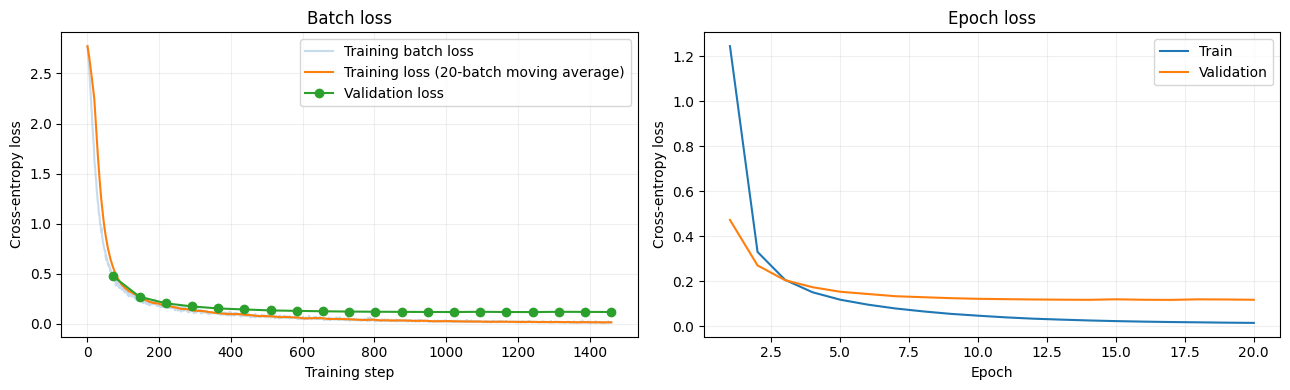

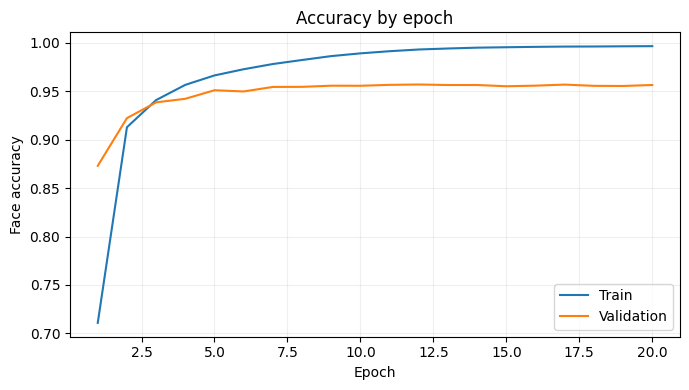

In [9]:
batch_log = pd.read_csv(root / 'batch_loss.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(batch_log['step'], batch_log['loss'], alpha=0.25, label='Training batch loss')
axes[0].plot(batch_log['step'], batch_log['loss'].rolling(20, min_periods=1).mean(),
             label='Training loss (20-batch moving average)')
axes[0].plot(history['step'], history['validation_loss'], marker='o', label='Validation loss')
axes[0].set(xlabel='Training step', ylabel='Cross-entropy loss', title='Batch loss')
for split in ['train', 'validation']:
    axes[1].plot(history['epoch'], history[f'{split}_loss'], label=split.capitalize())
axes[1].set(xlabel='Epoch', ylabel='Cross-entropy loss', title='Epoch loss')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for split in ['train', 'validation']:
    ax.plot(history['epoch'], history[f'{split}_accuracy'], label=split.capitalize())
ax.set(xlabel='Epoch', ylabel='Face accuracy', title='Accuracy by epoch')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Final cached results

Overall mean IoU includes stock. Per-class results use the reviewed names; recall is the fraction of faces of that class classified correctly.

In [10]:
from model_evaluation import read_cached_metrics
summary, per_class = read_cached_metrics(root, run['final_epoch'], run['class_names'])
display(summary.style.format({'faces': '{:,}', 'loss': '{:.4f}', 'accuracy': '{:.2%}', 'mean_iou': '{:.2%}'}))
summary.to_csv(root / 'summary.csv')
per_class.to_csv(root / 'per_class_metrics.csv', index=False)


,faces,loss,accuracy,mean_iou
split,,,,
train,"209,847",0.0133,99.70%,99.27%
validation,"70,255",0.1171,95.66%,90.32%


### Per-class results

In [11]:
for split in ['train', 'validation']:
    print(f"{split.capitalize()} — per-class results")
    table = per_class.loc[per_class['split'] == split].set_index(['class_index', 'class_name'])
    display(table[['support', 'recall', 'precision', 'iou']].style.format(
        {'support': '{:,}', 'recall': '{:.2%}', 'precision': '{:.2%}', 'iou': '{:.2%}'}))

Train — per-class results


,,support,recall,precision,iou
class_index,class_name,,,,
0,chamfer,"2,927",100.00%,100.00%,100.00%
1,triangular_passage,"9,605",97.38%,98.77%,96.21%
2,rectangular_passage,"13,077",99.13%,98.51%,97.66%
3,6sides_passage,"19,859",99.64%,99.01%,98.66%
4,triangular_through_slot,"5,778",100.00%,100.00%,100.00%
5,rectangular_through_slot,"8,508",98.20%,99.02%,97.25%
6,rectangular_through_step,"5,630",99.13%,99.59%,98.73%
7,2sides_through_step,"8,010",100.00%,100.00%,100.00%
8,slanted_through_step,"5,318",100.00%,100.00%,100.00%


Validation — per-class results


,,support,recall,precision,iou
class_index,class_name,,,,
0,chamfer,924,99.68%,100.00%,99.68%
1,triangular_passage,"2,985",77.29%,82.84%,66.62%
2,rectangular_passage,"4,390",87.74%,88.11%,78.45%
3,6sides_passage,"6,804",93.90%,90.69%,85.64%
4,triangular_through_slot,"1,892",99.79%,99.74%,99.53%
5,rectangular_through_slot,"2,883",83.04%,84.89%,72.35%
6,rectangular_through_step,"1,804",92.07%,92.07%,85.31%
7,2sides_through_step,"2,730",99.96%,99.96%,99.93%
8,slanted_through_step,"1,660",99.64%,99.52%,99.16%
